## 1. Planteamiento de la historia
La población de México en 2100 no es un número predeterminado. Los supuestos demográficos producen resultados muy distintos. Esta historia presenta primero el rango de escenarios, luego un contraste comprensible de tres escenarios y termina con las implicaciones de comunicar incertidumbre.

**Hipótesis comunicativa:** presentar solo un pronóstico ocultaría la variabilidad entre escenarios.

## 2. Importación y revisión de datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 58/practica")

df = pd.read_csv("ONU_Mexico_Poblacion_2100.csv")
print('Dimensiones:', df.shape)
display(df.head())
print('Valores nulos por columna:')
print(df.isna().sum())


Dimensiones: (12, 5)


,pais,anio,escenario,poblacion_miles,poblacion_millones
0,México,2100,Medio,130248.836,130.248836
1,México,2100,Alto,195043.492,195.043492
2,México,2100,Bajo,83851.707,83.851707
3,México,2100,Fecundidad constante,153175.131,153.175131
4,México,2100,Reemplazo instantáneo,175510.040,175.510040


Valores nulos por columna:
pais                  0
anio                  0
escenario             0
poblacion_miles       0
poblacion_millones    0
dtype: int64


## 3. Calidad, procedencia y transformación
Se comprueba la ausencia de duplicados, se conservan los nombres de los escenarios y se expresa la población en millones para facilitar su interpretación. No se mezclan estimaciones históricas con proyecciones.

In [2]:
assert not df.duplicated(['pais','anio','escenario']).any()
assert (df['poblacion_miles'] > 0).all()
df['poblacion_millones'] = df['poblacion_miles'] / 1000
display(df[['escenario','poblacion_millones']].sort_values('poblacion_millones'))

,escenario,poblacion_millones
2,Bajo,83.851707
6,Mortalidad constante,110.502995
11,Descenso acelerado de fecundidad adolescente,112.852554
10,Sin fecundidad antes de 18 años,121.027508
0,Medio,130.248836
7,Sin cambios,132.216280
5,Migración cero,139.315323
3,Fecundidad constante,153.175131
8,Impulso demográfico,165.645171
4,Reemplazo instantáneo,175.510040


## 4. Visualización 1: todos los escenarios

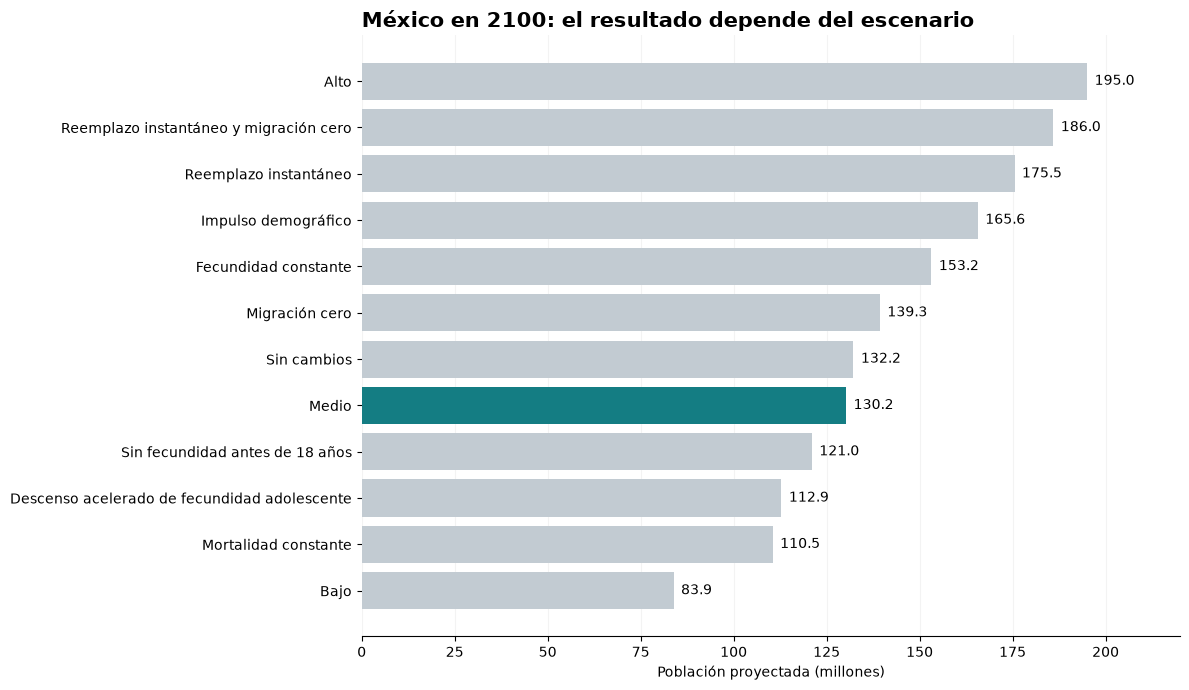

In [3]:
datos = df.sort_values('poblacion_millones')
colores = ['#147d83' if s == 'Medio' else '#c2cbd2' for s in datos['escenario']]
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(datos['escenario'], datos['poblacion_millones'], color=colores)
ax.set_xlim(0, 220)
ax.set_xlabel('Población proyectada (millones)')
ax.set_title('México en 2100: el resultado depende del escenario', loc='left', fontsize=15, weight='bold')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.grid(axis='x', alpha=0.15)
ax.set_axisbelow(True)
for i, valor in enumerate(datos['poblacion_millones']):
    ax.text(valor + 2, i, f'{valor:.1f}', va='center')
plt.tight_layout()
plt.savefig('grafico_escenarios.png', dpi=180, bbox_inches='tight')
plt.show()

**Interpretación:** el escenario medio apunta a 130.2 millones de habitantes. Los escenarios bajo y alto arrojan 83.9 y 195.0 millones, respectivamente. La amplitud entre ellos no representa un intervalo de confianza estadístico: refleja supuestos alternativos de proyección.

## 5. Visualización 2: tres escenarios principales

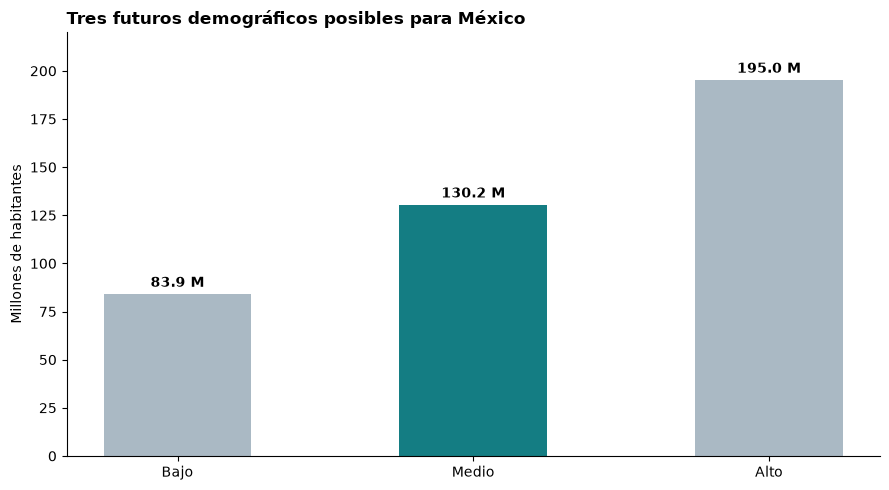

In [4]:
tres = df.set_index('escenario').loc[['Bajo', 'Medio', 'Alto']]
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(tres.index, tres['poblacion_millones'], color=['#aab9c4', '#147d83', '#aab9c4'], width=0.5)
ax.set_ylim(0, 220)
ax.set_ylabel('Millones de habitantes')
ax.set_title('Tres futuros demográficos posibles para México', loc='left', weight='bold')
ax.spines[['top','right']].set_visible(False)
for i, valor in enumerate(tres['poblacion_millones']):
    ax.text(i, valor + 4, f'{valor:.1f} M', ha='center', weight='bold')
plt.tight_layout()
plt.savefig('grafico_tres_escenarios.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Medidas para sostener el relato

In [5]:
medio = tres.loc['Medio', 'poblacion_millones']
bajo = tres.loc['Bajo', 'poblacion_millones']
alto = tres.loc['Alto', 'poblacion_millones']
print(f'Escenario medio: {medio:.2f} millones')
print(f'Diferencia alto-bajo: {alto-bajo:.2f} millones')
print(f'Razón alto/bajo: {alto/bajo:.2f} veces')

Escenario medio: 130.25 millones
Diferencia alto-bajo: 111.19 millones
Razón alto/bajo: 2.33 veces


## 7. Principios de visualización aplicados

### Gestalt
- **Similitud:** el gris agrupa los escenarios de contexto; el turquesa identifica el escenario medio.
- **Proximidad y continuidad:** categorías alineadas y ordenadas favorecen comparaciones sin saltos visuales.
- **Figura-fondo:** fondos blancos y cuadrículas tenues dirigen la atención a los datos.

### Edward Tufte
- **Alta proporción de tinta de datos:** se eliminan bordes y decoraciones sin función analítica.
- **Integridad gráfica:** las barras comienzan en cero, con unidades explícitas.
- **Etiquetas directas:** cifras junto a las barras evitan una leyenda innecesaria.

### Nigel Holmes
- **Narrativa memorable:** títulos con mensaje y un orden de lectura de lo general a lo particular.
- **Expresividad responsable:** el énfasis visual sirve a la idea central, sin iconos o efectos que distorsionen magnitudes.
- **Equilibrio:** se prioriza claridad y exactitud frente a la decoración.

## 8. Conclusiones
1. El escenario medio de Naciones Unidas sitúa la población mexicana en aproximadamente **130.2 millones en 2100**.
2. Los escenarios bajo y alto se separan por **111.2 millones de personas**, evidencia de que los supuestos importan.
3. Una visualización responsable no debe presentar escenarios hipotéticos como resultados garantizados.
4. Gestalt facilita el agrupamiento perceptivo; Tufte ayuda a preservar precisión; Holmes orienta el relato hacia un mensaje memorable.

**Limitaciones:** análisis transversal de un único año y país; no establece causas ni asigna probabilidades a los escenarios. Para profundizar se requerirían series temporales y desagregaciones por edad y sexo.

